In [1]:
# import libraries
import pandas as pd
import matplotlib.pyplot as plt
import json
import seaborn as sns
import numpy as np 

treutlein_set = 'treutlein_all_genes'
weinreb_set = 'weinreb_all_genes'

As a first step we are going to load all the files containing the data from the training, and test run of the neural networks and the interpretability techniques.

In [2]:
# hyperparameter search data from jsonl files
hyper_params_treutlein = []
with open (treutlein_set + '_hyper_params_log.jsonl', 'r') as f:
    for line in f:
        hyper_params_treutlein.append(json.loads(line))

hyper_params_weinreb = []
with open (weinreb_set + '_hyper_params_log.jsonl', 'r') as f:
    for line in f:
        hyper_params_weinreb.append(json.loads(line))

# final results data as json 
with open (treutlein_set + '_test_accuracy_best_hyper_params.json', 'r') as f:
    fnl_res_treutlein = json.load(f)
with open (weinreb_set + '_test_accuracy_best_hyper_params.json', 'r') as f:
    fnl_res_weinreb = json.load(f)


conf_matrix_treutlein = pd.read_csv(treutlein_set +'confusion_matrix.csv', index_col=0)
conf_matrix_weinreb = pd.read_csv(weinreb_set + 'confusion_matrix.csv', index_col=0)

integr_grad_treutlein = pd.read_csv(treutlein_set + '_integrated_gradient.csv')
integr_grad_weinreb = pd.read_csv(weinreb_set + '_integrated_gradient.csv')


We visualize the results from the hyperparameter search by displaying the validation accuracies from the random trials.

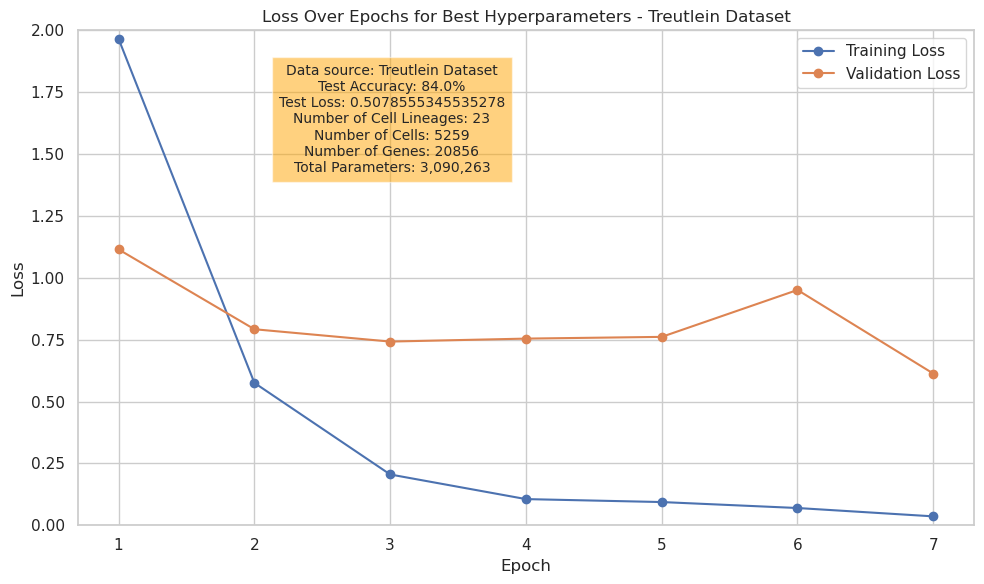

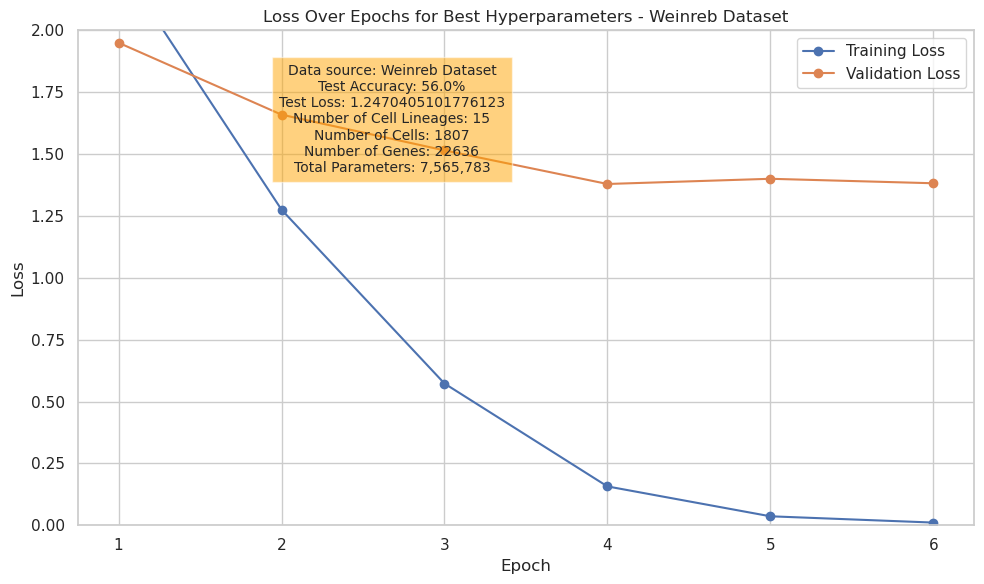

In [3]:
def calculate_parameters(config):
    input_size = config['data_overview']['number_of_genes']  # Number of input genes
    hidden_units = config['hyperparameters']['hidden_units']
    num_layers = config['hyperparameters']['num_layers']
    output_size = config['data_overview']['number_of_barcodes']  # Number of output classes (barcodes)

    # Parameters in the first layer
    params_first_layer = (input_size + 1) * hidden_units

    # Parameters in hidden layers
    params_hidden_layers = (hidden_units + 1) * hidden_units * (num_layers - 1)

    # Parameters in the output layer
    params_output_layer = (hidden_units + 1) * output_size

    return params_first_layer + params_hidden_layers + params_output_layer

def plot_losses(data, title, y_axis_limit=5):
    num_parameters = calculate_parameters(data)

    # Extracting training and validation loss data from the epochs
    num_epochs = len(data['training_run'])  # Automatically determine the number of epochs
    epochs = range(1, num_epochs + 1)
    training_losses = [data['training_run'][f'epoch_{i}']['training_loss'] for i in epochs]
    validation_losses = [data['training_run'][f'epoch_{i}']['validation_loss'] for i in epochs]

    # Styling the plot with seaborn
    sns.set(style='whitegrid')
    plt.figure(figsize=(10, 6))
    plt.plot(epochs, training_losses, label='Training Loss', marker='o')
    plt.plot(epochs, validation_losses, label='Validation Loss', marker='o')
    plt.ylim(0, y_axis_limit)  # Set the upper limit of y-axis dynamically

    # Title and labels
    plt.title(f'Loss Over Epochs for Best Hyperparameters - {title}')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    # Adding annotations
    test_acc = data['test_accuracy']
    test_loss = data['test_loss']
    num_barcodes = data['data_overview']['number_of_barcodes']
    num_cells = data['data_overview']['cells']
    num_genes = data['data_overview']['number_of_genes']
    info_text = (f"Data source: {title}\nTest Accuracy: {test_acc}%\n"
                 f"Test Loss: {test_loss}\nNumber of Cell Lineages: {num_barcodes}\n"
                 f"Number of Cells: {num_cells}\nNumber of Genes: {num_genes}\n"
                 f"Total Parameters: {num_parameters:,}")
    plt.figtext(0.4, 0.7, info_text, ha="center", fontsize=10, bbox={"facecolor":"orange", "alpha":0.5, "pad":5})

    plt.tight_layout()
    plt.savefig(f"/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/test_loss_epochs_{title}.pdf", dpi=300)

    plt.show()

# Example usage
plot_losses(fnl_res_treutlein, 'Treutlein Dataset', y_axis_limit=2)
plot_losses(fnl_res_weinreb, 'Weinreb Dataset', y_axis_limit=2)


Next, we are going to plot the training, and validation losses and also the test accuracy from training dense neural networks with the hyperparameters found by the previous step.

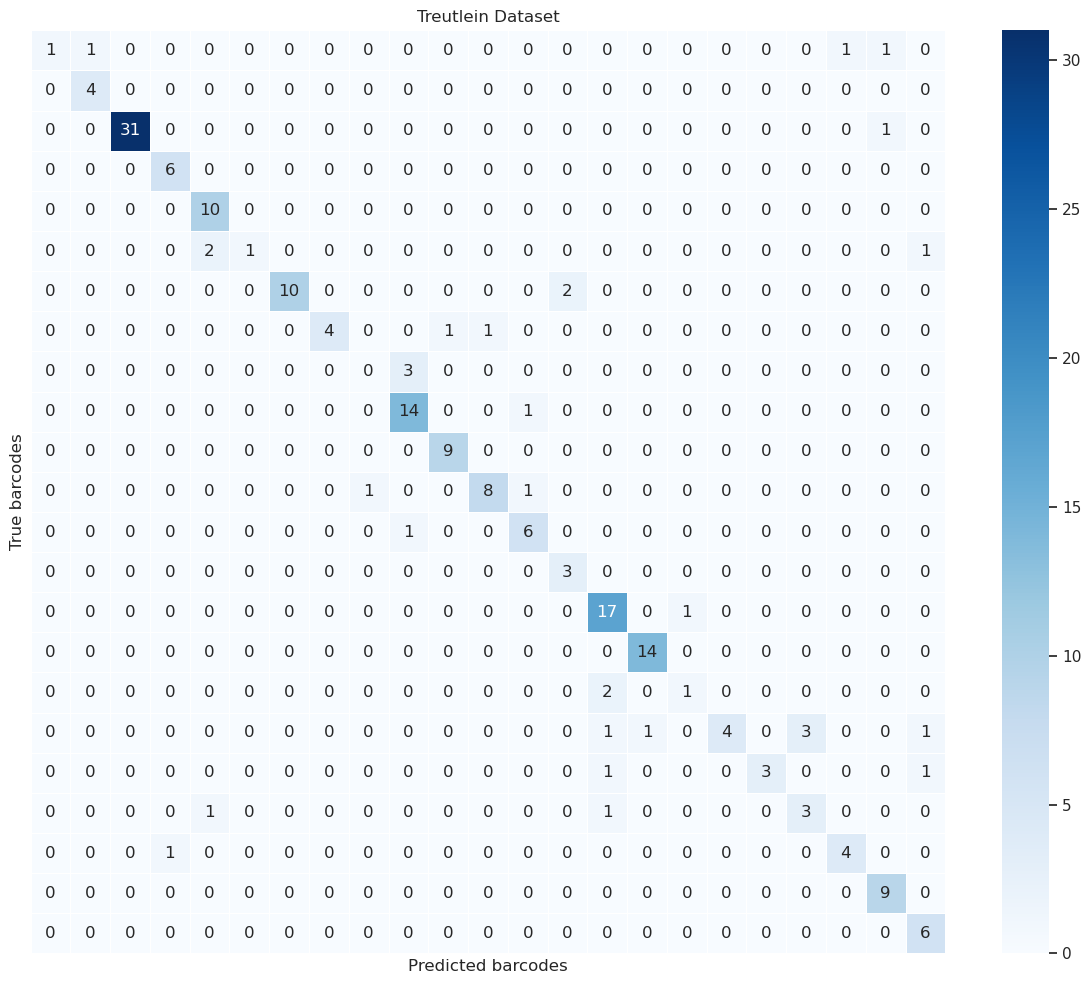

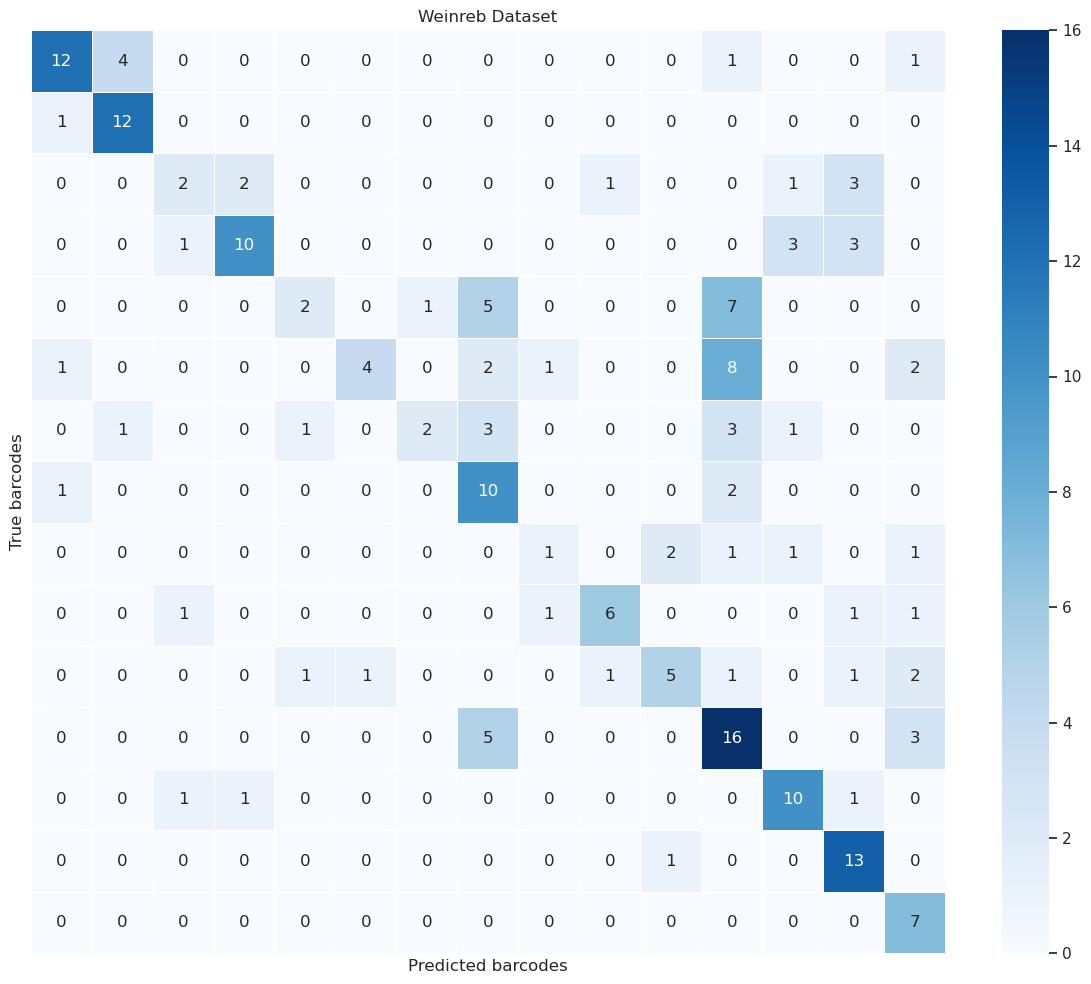

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_confusion_matrix(data, dataset_name):
    plt.figure(figsize=(12, 10))

    # Use a blue colormap similar to your figure
    sns.heatmap(
        data,
        annot=True,
        fmt='d',
        cmap='Blues',          # <-- blue colormap like your example
        linewidths=.5,
        cbar_kws={"label": ""} # no label on the colorbar
    )

    # Axis labels
    plt.xlabel("Predicted barcodes")
    plt.ylabel("True barcodes")

    # Remove barcode_cont or numeric tick labels
    plt.xticks([], [])   # remove all x tick labels
    plt.yticks([], [])   # remove all y tick labels

    plt.title(f"{dataset_name}")
    plt.tight_layout()

    plt.savefig(f"/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/confusion_matrix_{dataset_name}.pdf", dpi=300)
    plt.show()


plot_confusion_matrix(conf_matrix_treutlein, 'Treutlein Dataset')
plot_confusion_matrix(conf_matrix_weinreb, 'Weinreb Dataset')


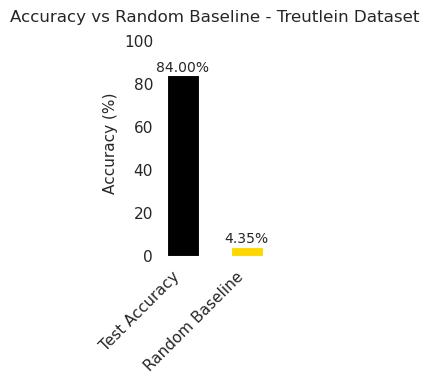

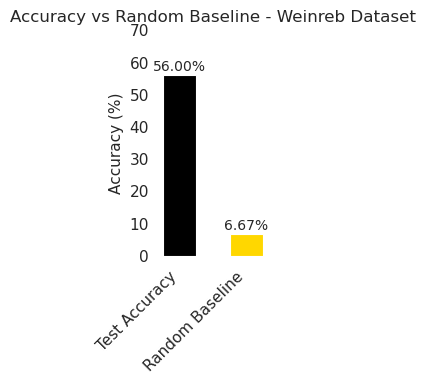

In [11]:
import matplotlib.pyplot as plt
import numpy as np

def plot_accuracy_vs_random_baseline(data, title, save_dir):
    # Extract values
    test_acc = data['test_accuracy']
    num_classes = data['data_overview']['number_of_barcodes']
    random_baseline = 100 * (1 / num_classes)  # in percent

    # Figure
    fig, ax = plt.subplots(figsize=(2, 4))

    # Bar plot (set colors explicitly)
    bars = ax.bar(
        ['Test Accuracy', 'Random Baseline'],
        [test_acc, random_baseline],
        width=0.5,
        linewidth=0.8,
        color=['black', '#FFD700']  # black + yellow
    )

    # Remove grid
    ax.grid(False)

    # Remove frame/spines
    for spine in ax.spines.values():
        spine.set_visible(False)

    # Restore y-axis
    ax.set_ylabel('Accuracy (%)', fontsize=11)
    ax.tick_params(axis='y', length=3, width=0.8)

    # Rotate x-axis labels
    plt.xticks(rotation=45, ha='right')

    # Title + limits
    ax.set_title(f'Accuracy vs Random Baseline - {title}', fontsize=12)
    ax.set_ylim(0, max(test_acc, random_baseline) * 1.25)

    # Annotate bars
    for bar, value in zip(bars, [test_acc, random_baseline]):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.4,
            f'{value:.2f}%',
            ha='center',
            va='bottom',
            fontsize=10
        )

    plt.tight_layout()
    plt.savefig(f"{save_dir}/accuracy_vs_random_baseline_{title.replace(' ', '_')}.pdf", dpi=300)
    plt.show()


# Save directory
save_dir = "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures"

plot_accuracy_vs_random_baseline(fnl_res_treutlein, "Treutlein Dataset", save_dir)
plot_accuracy_vs_random_baseline(fnl_res_weinreb, "Weinreb Dataset", save_dir)

In [20]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

def plot_lime_vs_integrated_gradient(
    dataset_name,
    dataset_label=None,
    highlight_genes=("eGFP",),
    top_lime=10,
    top_ig=10,
    figsize=(10.5, 7.0),
    save=True,
):
    OUTPUT_DIR = (
        "/fast/AG_Metzger/philipp/python_files/"
        "gene_signature/mutual_information_approach/"
        "November_25_ReDo/figures/"
    )
    os.makedirs(OUTPUT_DIR, exist_ok=True)

    # ----------------------------
    # Load data
    # ----------------------------
    integr_grad_csv = f"{dataset_name}_integrated_gradient.csv"
    lime_csv        = f"{dataset_name}_lime.csv"

    ig = pd.read_csv(integr_grad_csv)
    li = pd.read_csv(lime_csv)

    ig = ig.loc[ig["barcode_cont"] == -1, ["gene", "score"]].copy()
    ig["ig_score"] = ig["score"].abs()

    li = li.loc[li["barcode_cont"] == -1].copy()
    if "lime_score" in li.columns:
        li = li[["gene", "lime_score"]]
    else:
        li = li[["gene", "score"]].rename(columns={"score": "lime_score"})

    df = pd.merge(ig[["gene", "ig_score"]], li, on="gene").dropna()

    # ----------------------------
    # Rank sets
    # ----------------------------
    top_lime_df = df.nlargest(top_lime, "lime_score")
    top_ig_df   = df.nlargest(top_ig, "ig_score")
    highlight_df = df[df["gene"].isin(set(highlight_genes))] if highlight_genes else pd.DataFrame()

    # ----------------------------
    # Correlation
    # ----------------------------
    r = df["lime_score"].corr(df["ig_score"])

    # ----------------------------
    # Plot
    # ----------------------------
    fig, ax = plt.subplots(figsize=figsize)

    ax.scatter(df["lime_score"], df["ig_score"], s=18, alpha=0.45, linewidths=0)
    ax.scatter(top_lime_df["lime_score"], top_lime_df["ig_score"], s=55)
    ax.scatter(top_ig_df["lime_score"], top_ig_df["ig_score"], s=65)

    if not highlight_df.empty:
        ax.scatter(highlight_df["lime_score"], highlight_df["ig_score"], s=70)

    for _, row in top_lime_df.iterrows():
        ax.annotate(
            row["gene"],
            (row["lime_score"], row["ig_score"]),
            xytext=(6, 4),
            textcoords="offset points",
            fontsize=12
        )

    for _, row in top_ig_df.iterrows():
        ax.annotate(
            row["gene"],
            (row["lime_score"], row["ig_score"]),
            xytext=(6, 4),
            textcoords="offset points",
            fontsize=12,
            color="red"
        )

    for _, row in highlight_df.iterrows():
        ax.annotate(
            row["gene"],
            (row["lime_score"], row["ig_score"]),
            xytext=(6, 4),
            textcoords="offset points",
            fontsize=12,
            color="red"
        )

    ax.set_xlabel("LIME Score", fontsize=14)
    ax.set_ylabel("Integrated Gradient Score", fontsize=14)

    # ----------------------------
    # Clean axis styling
    # ----------------------------
    ax.grid(False)
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.text(0.74, 0.60, f"r : {r:.3f}", transform=ax.transAxes, fontsize=14)

    if dataset_label:
        ax.text(0.57, 0.90, dataset_label, transform=ax.transAxes, fontsize=18)

    legend_handles = [
        Line2D([0], [0], marker="o", color="w", label="All Genes",
               markerfacecolor="C0", markersize=7, alpha=0.7),
        Line2D([0], [0], marker="o", color="w", label=f"Top {top_lime} LIME",
               markerfacecolor="C1", markersize=7),
        Line2D([0], [0], marker="o", color="w", label=f"Top {top_ig} IG",
               markerfacecolor="C3", markersize=7),
    ]
    ax.legend(handles=legend_handles, frameon=False, loc="center right")

    plt.tight_layout()

    if save:
        out_file = os.path.join(
            OUTPUT_DIR,
            f"{dataset_name}_LIME_vs_IG.pdf"
        )
        plt.savefig(out_file, dpi=300)
        print(f"[saved] {out_file}")

    plt.show()


[saved] /fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/treutlein_all_genes_LIME_vs_IG.pdf


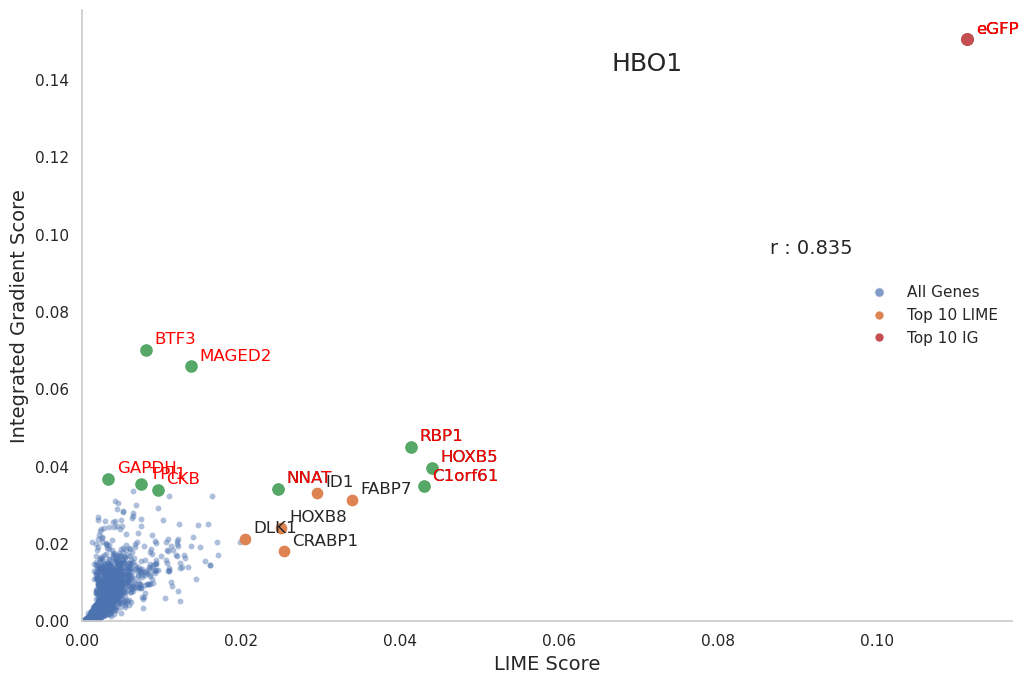

In [21]:
plot_lime_vs_integrated_gradient(
    dataset_name="treutlein_all_genes",
    dataset_label="HBO1",
    highlight_genes=("eGFP",),
)


[saved] /fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/weinreb_all_genes_LIME_vs_IG.pdf


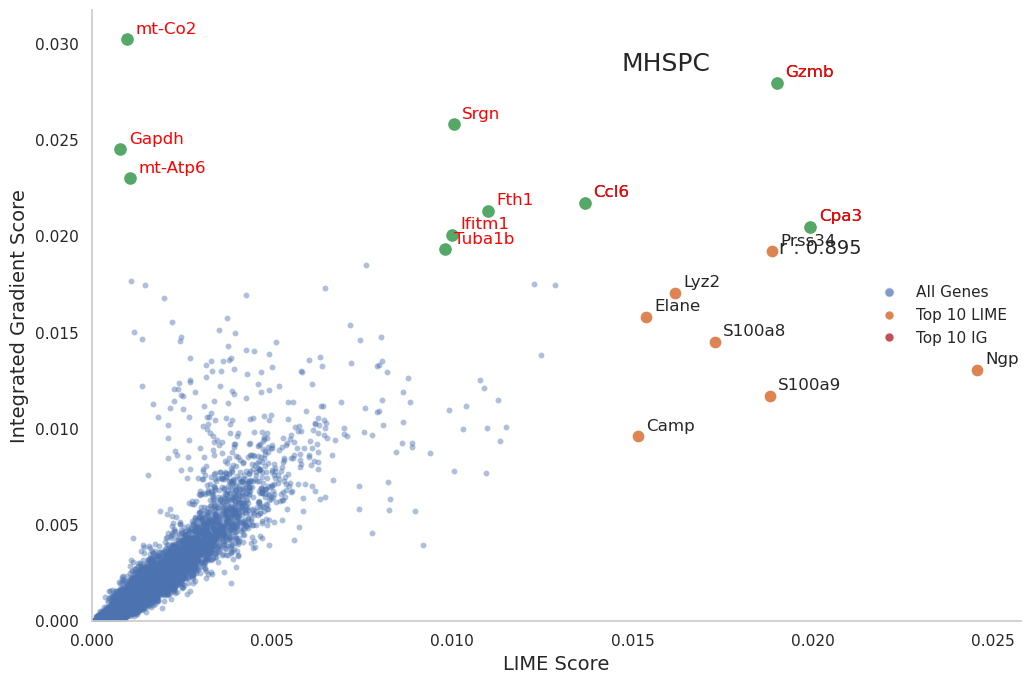

In [22]:
plot_lime_vs_integrated_gradient(
    dataset_name="weinreb_all_genes",
    dataset_label="MHSPC",
    highlight_genes=("eGFP",),
)
